# **RenalInsight: An Explainable Machine Learning-Based System for Chronic Kidney Disease Prediction and Risk Analysis**

## **Step 1 — Install/import libraries and load the dataset**

In [ ]:
# Install required libraries
!pip install -q xgboost shap ucimlrepo

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

In [ ]:
# Load UCI Risk Factor Prediction of CKD dataset
ckd = fetch_ucirepo(id=857)

# Features and target
X = ckd.data.features
y = ckd.data.targets

# Combine into one DataFrame
df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (200, 29)


,bp (Diastolic),bp limit,sg,al,rbc,su,pc,pcc,ba,bgr,...,dm,cad,appet,pe,ane,grf,stage,affected,age,class
0,0,0,1.019 - 1.021,1-Jan,0,< 0,0,0,0,< 112,...,0,0,0,0,0,≥ 227.944,s1,1,< 12,ckd
1,0,0,1.009 - 1.011,< 0,0,< 0,0,0,0,112 - 154,...,0,0,0,0,0,≥ 227.944,s1,1,< 12,ckd
2,0,0,1.009 - 1.011,≥ 4,1,< 0,1,0,1,< 112,...,0,0,1,0,0,127.281 - 152.446,s1,1,< 12,ckd
3,1,1,1.009 - 1.011,3-Mar,0,< 0,0,0,0,112 - 154,...,0,0,0,0,0,127.281 - 152.446,s1,1,< 12,ckd
4,0,0,1.015 - 1.017,< 0,0,< 0,0,0,0,154 - 196,...,1,0,1,1,0,127.281 - 152.446,s1,1,20-Dec,ckd


## **Step 2 — Basic dataset inspection**


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape:
(200, 29)

Column Names:
['bp (Diastolic)', 'bp limit', 'sg', 'al', 'rbc', 'su', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sod', 'sc', 'pot', 'hemo', 'pcv', 'rbcc', 'wbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'grf', 'stage', 'affected', 'age', 'class']

Data Types:
bp (Diastolic)     int64
bp limit           int64
sg                object
al                object
rbc                int64
su                object
pc                 int64
pcc                int64
ba                 int64
bgr               object
bu                object
sod               object
sc                object
pot               object
hemo              object
pcv               object
rbcc              object
wbcc              object
htn                int64
dm                 int64
cad                int64
appet              int64
pe                 int64
ane                int64
grf               object
stage             object
affected           int64
age               object
class             obje

,bp (Diastolic),bp limit,sg,al,rbc,su,pc,pcc,ba,bgr,...,dm,cad,appet,pe,ane,grf,stage,affected,age,class
0,0,0,1.019 - 1.021,1-Jan,0,< 0,0,0,0,< 112,...,0,0,0,0,0,≥ 227.944,s1,1,< 12,ckd
1,0,0,1.009 - 1.011,< 0,0,< 0,0,0,0,112 - 154,...,0,0,0,0,0,≥ 227.944,s1,1,< 12,ckd
2,0,0,1.009 - 1.011,≥ 4,1,< 0,1,0,1,< 112,...,0,0,1,0,0,127.281 - 152.446,s1,1,< 12,ckd
3,1,1,1.009 - 1.011,3-Mar,0,< 0,0,0,0,112 - 154,...,0,0,0,0,0,127.281 - 152.446,s1,1,< 12,ckd
4,0,0,1.015 - 1.017,< 0,0,< 0,0,0,0,154 - 196,...,1,0,1,1,0,127.281 - 152.446,s1,1,20-Dec,ckd



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   bp (Diastolic)  200 non-null    int64 
 1   bp limit        200 non-null    int64 
 2   sg              200 non-null    object
 3   al              200 non-null    object
 4   rbc             200 non-null    int64 
 5   su              200 non-null    object
 6   pc              200 non-null    int64 
 7   pcc             200 non-null    int64 
 8   ba              200 non-null    int64 
 9   bgr             200 non-null    object
 10  bu              200 non-null    object
 11  sod             200 non-null    object
 12  sc              200 non-null    object
 13  pot             200 non-null    object
 14  hemo            200 non-null    object
 15  pcv             200 non-null    object
 16  rbcc            200 non-null    object
 17  wbcc            200 non-null    

## **Step 3 — Check missing values**

In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percentage
bp (Diastolic),0,0.0
bp limit,0,0.0
sg,0,0.0
al,0,0.0
rbc,0,0.0
su,0,0.0
pc,0,0.0
pcc,0,0.0
ba,0,0.0
bgr,0,0.0


## **Step 4 — Check duplicates**

In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    display(df[df.duplicated(keep=False)])

Number of duplicate rows: 0


## **Step 5 — Inspect the target**

In [ ]:
print("Target column:")
print(y.columns.tolist())

target_column = y.columns[0]

print("\nTarget values:")
print(df[target_column].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    df[target_column]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Target column:
['class']

Target values:
class
ckd       128
notckd     72
Name: count, dtype: int64

Target percentages:
class
ckd       64.0
notckd    36.0
Name: proportion, dtype: float64


## **Step 6 — Check all unique values**

In [ ]:
for column in df.columns:
    print(f"\n{'='*60}")
    print(f"Column: {column}")
    print("Data type:", df[column].dtype)
    print("Unique values:", df[column].nunique())
    print(df[column].unique()[:20])


Column: bp (Diastolic)
Data type: int64
Unique values: 2
[0 1]

Column: bp limit
Data type: int64
Unique values: 3
[0 1 2]

Column: sg
Data type: object
Unique values: 5
['1.019 - 1.021' '1.009 - 1.011' '1.015 - 1.017' '≥ 1.023' '< 1.007']

Column: al
Data type: object
Unique values: 5
['1-Jan' '< 0' '≥ 4' '3-Mar' '2-Feb']

Column: rbc
Data type: int64
Unique values: 2
[0 1]

Column: su
Data type: object
Unique values: 6
['< 0' '4-Apr' '2-Feb' '4-Mar' '2-Jan' '≥ 4']

Column: pc
Data type: int64
Unique values: 2
[0 1]

Column: pcc
Data type: int64
Unique values: 2
[0 1]

Column: ba
Data type: int64
Unique values: 2
[0 1]

Column: bgr
Data type: object
Unique values: 10
['< 112' '112 - 154' '154 - 196' '406 - 448' '238 - 280' '196 - 238'
 '≥ 448' '280 - 322' '364 - 406' '322 - 364']

Column: bu
Data type: object
Unique values: 8
['< 48.1' '48.1 - 86.2' '200.5 - 238.6' '124.3 - 162.4' '86.2 - 124.3'
 '162.4 - 200.5' '≥ 352.9' '238.6 - 276.7']

Column: sod
Data type: object
Unique values:

## **Step 7 — Check the potentially problematic variables**

In [ ]:
for column in ["stage", "grf", target_column]:
    if column in df.columns:
        print(f"\n--- {column} ---")
        print(df[column].value_counts(dropna=False))


--- stage ---
stage
s1    54
s4    45
s2    35
s5    35
s3    31
Name: count, dtype: int64

--- grf ---
grf
< 26.6175            68
26.6175 - 51.7832    38
51.7832 - 76.949     28
76.949 - 102.115     17
102.115 - 127.281    15
127.281 - 152.446    11
152.446 - 177.612     9
177.612 - 202.778     8
202.778 - 227.944     3
≥ 227.944             2
 p                    1
Name: count, dtype: int64

--- class ---
class
ckd       128
notckd     72
Name: count, dtype: int64


## **Step 8 - Data Cleaning & Feature Preparation**

In [ ]:
# 8.1 clean column names:
data = df.copy()

# Remove unnecessary spaces from column names
data.columns = data.columns.str.strip()

print("Columns:")
print(data.columns.tolist())

Columns:
['bp (Diastolic)', 'bp limit', 'sg', 'al', 'rbc', 'su', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sod', 'sc', 'pot', 'hemo', 'pcv', 'rbcc', 'wbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'grf', 'stage', 'affected', 'age', 'class']


In [ ]:
# 8.2 Remove Leakage Column
leakage_columns = ["stage", "grf"]

data_model = data.drop(columns=leakage_columns)

print("Removed columns:", leakage_columns)
print("New shape:", data_model.shape)

data_model.head()

Removed columns: ['stage', 'grf']
New shape: (200, 27)


,bp (Diastolic),bp limit,sg,al,rbc,su,pc,pcc,ba,bgr,...,wbcc,htn,dm,cad,appet,pe,ane,affected,age,class
0,0,0,1.019 - 1.021,1-Jan,0,< 0,0,0,0,< 112,...,7360 - 9740,0,0,0,0,0,0,1,< 12,ckd
1,0,0,1.009 - 1.011,< 0,0,< 0,0,0,0,112 - 154,...,12120 - 14500,0,0,0,0,0,0,1,< 12,ckd
2,0,0,1.009 - 1.011,≥ 4,1,< 0,1,0,1,< 112,...,14500 - 16880,0,0,0,1,0,0,1,< 12,ckd
3,1,1,1.009 - 1.011,3-Mar,0,< 0,0,0,0,112 - 154,...,7360 - 9740,0,0,0,0,0,0,1,< 12,ckd
4,0,0,1.015 - 1.017,< 0,0,< 0,0,0,0,154 - 196,...,7360 - 9740,0,1,0,1,1,0,1,20-Dec,ckd


In [ ]:
# 8.3 Seperating Future and Target:
X = data_model.drop(columns=["class"])
y = data_model["class"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

X shape: (200, 26)
y shape: (200,)

Target distribution:
class
ckd       128
notckd     72
Name: count, dtype: int64


In [ ]:
# 8.4 — Inspect all categorical/object columns
object_columns = X.select_dtypes(include="object").columns.tolist()

print("Object columns:" , object_columns)

for col in object_columns:
    print(f"\n{'='*60}")
    print(f"Column: {col}")
    print(X[col].value_counts(dropna=False))

Object columns:
['sg', 'al', 'su', 'bgr', 'bu', 'sod', 'sc', 'pot', 'hemo', 'pcv', 'rbcc', 'wbcc', 'age']

Column: sg
sg
1.019 - 1.021    75
1.009 - 1.011    45
≥ 1.023          41
1.015 - 1.017    36
< 1.007           3
Name: count, dtype: int64

Column: al
al
< 0      116
2-Feb     27
3-Mar     23
1-Jan     21
≥ 4       13
Name: count, dtype: int64

Column: su
su
< 0      170
2-Feb      9
4-Mar      8
4-Apr      6
2-Jan      6
≥ 4        1
Name: count, dtype: int64

Column: bgr
bgr
112 - 154    79
< 112        70
196 - 238    14
154 - 196    13
238 - 280    11
406 - 448     4
280 - 322     4
≥ 448         3
364 - 406     1
322 - 364     1
Name: count, dtype: int64

Column: bu
bu
< 48.1           108
48.1 - 86.2       53
86.2 - 124.3      16
124.3 - 162.4     11
200.5 - 238.6      5
162.4 - 200.5      5
≥ 352.9            1
238.6 - 276.7      1
Name: count, dtype: int64

Column: sod
sod
133 - 138    92
138 - 143    49
143 - 148    22
128 - 133    14
148 - 153     9
123 - 128     6
< 1

In [ ]:
# 8.5 — Clean whitespace in object columns
for col in object_columns:
    X[col] = X[col].astype(str).str.strip()

print("String cleaning completed.")

String cleaning completed.


In [ ]:
# 8.6 — Convert binary target: ckd -> 1 , notckd -> 0
y = y.str.strip().str.lower()

target_mapping = {
    "ckd": 1,
    "notckd": 0
}

y = y.map(target_mapping)
print("Encoded target:")
print(y.value_counts())

print("\nMissing target values:", y.isna().sum())

Encoded target:
class
1    128
0     72
Name: count, dtype: int64

Missing target values: 0


In [ ]:
# 8.7 — Identify binary columns
binary_columns = []

for col in X.columns:
    unique_values = X[col].dropna().unique()
    if len(unique_values) <= 2:
        binary_columns.append(col)

print("Binary columns:")
print(binary_columns)

Binary columns:
['bp (Diastolic)', 'rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'affected']


In [ ]:
# 8.8 — Check numerical-looking categorical variables
# Some columns such as bgr, bu, sod, sc, pot, hemo, etc. are stored as ranges.
range_columns = ["sg","al","su","bgr","bu","sod","sc","pot","hemo","pcv","rbcc","wbcc","age"]
for col in range_columns:
    if col in X.columns:
        print(f"\n--- {col} ---")
        print(X[col].unique())


--- sg ---
['1.019 - 1.021' '1.009 - 1.011' '1.015 - 1.017' '≥ 1.023' '< 1.007']

--- al ---
['1-Jan' '< 0' '≥ 4' '3-Mar' '2-Feb']

--- su ---
['< 0' '4-Apr' '2-Feb' '4-Mar' '2-Jan' '≥ 4']

--- bgr ---
['< 112' '112 - 154' '154 - 196' '406 - 448' '238 - 280' '196 - 238'
 '≥ 448' '280 - 322' '364 - 406' '322 - 364']

--- bu ---
['< 48.1' '48.1 - 86.2' '200.5 - 238.6' '124.3 - 162.4' '86.2 - 124.3'
 '162.4 - 200.5' '≥ 352.9' '238.6 - 276.7']

--- sod ---
['138 - 143' '133 - 138' '123 - 128' '143 - 148' '148 - 153' '< 118'
 '128 - 133' '118 - 123' '≥ 158']

--- sc ---
['< 3.65' '3.65 - 6.8' '16.25 - 19.4' '6.8 - 9.95' '13.1 - 16.25'
 '9.95 - 13.1' '≥ 28.85']

--- pot ---
['< 7.31' '≥ 42.59' '7.31 - 11.72' '38.18 - 42.59']

--- hemo ---
['11.3 - 12.6' '8.7 - 10' '13.9 - 15.2' '≥ 16.5' '10 - 11.3' '7.4 - 8.7'
 '12.6 - 13.9' '15.2 - 16.5' '< 6.1' '6.1 - 7.4']

--- pcv ---
['33.5 - 37.4' '29.6 - 33.5' '41.3 - 45.2' '37.4 - 41.3' '≥ 49.1'
 '21.8 - 25.7' '45.2 - 49.1' '< 17.9' '25.7 - 29.6' '1

In [ ]:
# 8.9 — Prepare the categorical features
print("Rows containing '20-Dec':")

display(
    data_model[
        data_model["age"].astype(str).str.strip() == "20-Dec"
    ]
)

Rows containing '20-Dec':


,bp (Diastolic),bp limit,sg,al,rbc,su,pc,pcc,ba,bgr,...,wbcc,htn,dm,cad,appet,pe,ane,affected,age,class
4,0,0,1.015 - 1.017,< 0,0,< 0,0,0,0,154 - 196,...,7360 - 9740,0,1,0,1,1,0,1,20-Dec,ckd
5,1,1,≥ 1.023,< 0,0,< 0,0,0,0,< 112,...,4980 - 7360,0,0,0,0,0,0,0,20-Dec,notckd
6,0,0,1.019 - 1.021,3-Mar,0,< 0,0,0,0,< 112,...,7360 - 9740,1,1,0,0,0,0,1,20-Dec,ckd
7,0,0,1.019 - 1.021,< 0,0,< 0,0,0,0,112 - 154,...,4980 - 7360,0,0,0,0,0,0,1,20-Dec,ckd


In [ ]:
# 8.10 Find Suspicious Range Values
for col in object_columns:
    values = X[col].astype(str).str.strip()

    suspicious = values[
        values.str.contains(
            r'[A-Za-z]',
            regex=True,
            na=False
        )
    ].unique()

    if len(suspicious) > 0:
        print(f"\n{col}:")
        print(suspicious)


al:
['1-Jan' '3-Mar' '2-Feb']

su:
['4-Apr' '2-Feb' '4-Mar' '2-Jan']

age:
['20-Dec']


In [ ]:
# 8.11 — Inspecting UCI Dataset

print("UCI Dataset ID:")
print(ckd.metadata.uci_id)

print("\nDataset Name:")
print(ckd.metadata.name)

print("\nDataset Description:")
print(ckd.metadata.description)

print("\nDataset DOI:")
print(ckd.metadata.doi)

print("\nVariables:")
display(ckd.variables)

UCI Dataset ID:
857

Dataset Name:
Risk Factor Prediction of Chronic Kidney Disease

Dataset Description:
None

Dataset DOI:
None

Variables:


,name,role,type,demographic,description,units,missing_values
0,bp (Diastolic),Feature,Integer,None,None,None,no
1,bp limit,Feature,Integer,None,None,None,no
2,sg,Feature,Categorical,None,None,None,no
3,al,Feature,Categorical,None,None,None,no
4,class,Target,Binary,None,None,None,no
5,rbc,Feature,Integer,None,None,None,no
6,su,Feature,Categorical,None,None,None,no
7,pc,Feature,Integer,None,None,None,no
8,pcc,Feature,Integer,None,None,None,no
9,ba,Feature,Integer,None,None,None,no


In [ ]:
X_uci = ckd.data.features.copy()
y_uci = ckd.data.targets.copy()

print("Features shape:", X_uci.shape)
print("Target shape:", y_uci.shape)

print("\nFeature columns:")
print(X_uci.columns.tolist())

print("\nAge values:")
print(X_uci["age"].value_counts(dropna=False))

print("\nAlbumin (al) values:")
print(X_uci["al"].value_counts(dropna=False))

print("\nSugar (su) values:")
print(X_uci["su"].value_counts(dropna=False))

Features shape: (200, 28)
Target shape: (200, 1)

Feature columns:
['bp (Diastolic)', 'bp limit', 'sg', 'al', 'rbc', 'su', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sod', 'sc', 'pot', 'hemo', 'pcv', 'rbcc', 'wbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'grf', 'stage', 'affected', 'age']

Age values:
age
59 - 66    48
66 - 74    34
51 - 59    33
43 - 51    31
27 - 35    14
35 - 43    12
20 - 27    10
≥ 74       10
20-Dec      4
< 12        4
Name: count, dtype: int64

Albumin (al) values:
al
< 0      116
2-Feb     27
3-Mar     23
1-Jan     21
≥ 4       13
Name: count, dtype: int64

Sugar (su) values:
su
< 0      170
2-Feb      9
4-Mar      8
4-Apr      6
2-Jan      6
≥ 4        1
Name: count, dtype: int64


In [ ]:
print("Rows where age = '20-Dec':")

display(
    X_uci[
        X_uci["age"].astype(str).str.strip() == "20-Dec"
    ]
)

print("\nRows where al contains date-like values:")
display(
    X_uci[
        X_uci["al"].astype(str).str.contains(
            r"\d+-[A-Za-z]+",
            regex=True,
            na=False
        )
    ][["al"]]
)

print("\nRows where su contains date-like values:")
display(
    X_uci[
        X_uci["su"].astype(str).str.contains(
            r"\d+-[A-Za-z]+",
            regex=True,
            na=False
        )
    ][["su"]]
)

Rows where age = '20-Dec':


,bp (Diastolic),bp limit,sg,al,rbc,su,pc,pcc,ba,bgr,...,htn,dm,cad,appet,pe,ane,grf,stage,affected,age
4,0,0,1.015 - 1.017,< 0,0,< 0,0,0,0,154 - 196,...,0,1,0,1,1,0,127.281 - 152.446,s1,1,20-Dec
5,1,1,≥ 1.023,< 0,0,< 0,0,0,0,< 112,...,0,0,0,0,0,0,102.115 - 127.281,s1,0,20-Dec
6,0,0,1.019 - 1.021,3-Mar,0,< 0,0,0,0,< 112,...,1,1,0,0,0,0,177.612 - 202.778,s1,1,20-Dec
7,0,0,1.019 - 1.021,< 0,0,< 0,0,0,0,112 - 154,...,0,0,0,0,0,0,26.6175 - 51.7832,s4,1,20-Dec



Rows where al contains date-like values:


,al
0,1-Jan
3,3-Mar
6,3-Mar
13,2-Feb
23,1-Jan
...,...
186,3-Mar
192,3-Mar
193,1-Jan
194,2-Feb



Rows where su contains date-like values:


,su
13,4-Apr
64,2-Feb
71,4-Apr
82,4-Mar
86,4-Mar
94,4-Apr
98,2-Jan
112,4-Mar
113,2-Feb
114,2-Feb


In [ ]:
# 8.12 - Correct Data format artifacts
# Work from the original UCI features
X_clean = ckd.data.features.copy()

# Remove whitespace
for col in X_clean.select_dtypes(include="object").columns:
    X_clean[col] = X_clean[col].astype(str).str.strip()

# Correct Albumin (al)
al_mapping = {
    "1-Jan": "1",
    "2-Feb": "2",
    "3-Mar": "3"
}
X_clean["al"] = X_clean["al"].replace(al_mapping)

# Correct Sugar (su)
su_mapping = {
    "2-Jan": "2",
    "2-Feb": "2",
    "3-Mar": "3",
    "4-Mar": "3",
    "4-Apr": "4"
}
X_clean["su"] = X_clean["su"].replace(su_mapping)

# Correct age
age_mapping = {
    "20-Dec": "12 - 20"
}

X_clean["age"] = X_clean["age"].replace(age_mapping)
print("Corrections completed.")

Corrections completed.


In [ ]:
# 8.13 Verifying Corrections

print("AL values:")
print(X_clean["al"].value_counts().sort_index())

print("\nSU values:")
print(X_clean["su"].value_counts().sort_index())

print("\nAGE values:")
print(X_clean["age"].value_counts().sort_index())

AL values:
al
1       21
2       27
3       23
< 0    116
≥ 4     13
Name: count, dtype: int64

SU values:
su
2       15
3        8
4        6
< 0    170
≥ 4      1
Name: count, dtype: int64

AGE values:
age
12 - 20     4
20 - 27    10
27 - 35    14
35 - 43    12
43 - 51    31
51 - 59    33
59 - 66    48
66 - 74    34
< 12        4
≥ 74       10
Name: count, dtype: int64


In [ ]:
# 8.14 Remove Leakage Prone Features

X_clean = X_clean.drop(columns=["grf", "stage"])

print("Final feature count:", X_clean.shape[1])
print("\nRemaining features:")
print(X_clean.columns.tolist())

Final feature count: 26

Remaining features:
['bp (Diastolic)', 'bp limit', 'sg', 'al', 'rbc', 'su', 'pc', 'pcc', 'ba', 'bgr', 'bu', 'sod', 'sc', 'pot', 'hemo', 'pcv', 'rbcc', 'wbcc', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane', 'affected', 'age']


In [ ]:
# 8.15 Investigating "affected" Feature

print("Affected value counts:")
print(X_clean["affected"].value_counts(dropna=False))

print("\nAffected data type:")
print(X_clean["affected"].dtype)

print("\nAffected vs CKD target:")
display(
    pd.crosstab(
        X_clean["affected"],
        ckd.data.targets["class"]
    )
)

Affected value counts:
affected
1    128
0     72
Name: count, dtype: int64

Affected data type:
int64

Affected vs CKD target:


class,ckd,notckd
affected,,
0,0,72
1,128,0


In [ ]:
# 8.16 Checking "affected" against stage/grf

verification_df = ckd.data.features[
    ["affected", "stage", "grf"]
].copy()

print("Affected vs Stage:")
display(pd.crosstab(
    verification_df["affected"],
    verification_df["stage"]
))

print("\nAffected vs GRF:")
display(pd.crosstab(
    verification_df["affected"],
    verification_df["grf"]
))

Affected vs Stage:


stage,s1,s2,s3,s4,s5
affected,,,,,
0,45,23,0,4,0
1,9,12,31,41,35



Affected vs GRF:


grf,p,102.115 - 127.281,127.281 - 152.446,152.446 - 177.612,177.612 - 202.778,202.778 - 227.944,26.6175 - 51.7832,51.7832 - 76.949,76.949 - 102.115,< 26.6175,≥ 227.944
affected,,,,,,,,,,,
0,0,12,8,9,7,3,2,16,13,2,0
1,1,3,3,0,1,0,36,12,4,66,2


In [ ]:
# 8.17 Final Feature Overivew:

feature_summary = pd.DataFrame({
    "Feature": X_clean.columns,
    "Data_Type": X_clean.dtypes.astype(str).values,
    "Unique_Values": [
        X_clean[col].nunique()
        for col in X_clean.columns
    ]
})

display(feature_summary)

,Feature,Data_Type,Unique_Values
0,bp (Diastolic),int64,2
1,bp limit,int64,3
2,sg,object,5
3,al,object,5
4,rbc,int64,2
5,su,object,5
6,pc,int64,2
7,pcc,int64,2
8,ba,int64,2
9,bgr,object,10


In [ ]:
# 8.18 Removing target leakage features

leakage_columns = [ "grf", "stage", "affected"]

X_final = X_clean.drop(columns=leakage_columns, errors="ignore")

print("Removed leakage features:", leakage_columns)
print("\nFinal feature count:", X_final.shape[1])
print("\nFinal features:")
for i, col in enumerate(X_final.columns, start=1):
    print(f"{i:2}. {col}")

Removed leakage features: ['grf', 'stage', 'affected']

Final feature count: 25

Final features:
 1. bp (Diastolic)
 2. bp limit
 3. sg
 4. al
 5. rbc
 6. su
 7. pc
 8. pcc
 9. ba
10. bgr
11. bu
12. sod
13. sc
14. pot
15. hemo
16. pcv
17. rbcc
18. wbcc
19. htn
20. dm
21. cad
22. appet
23. pe
24. ane
25. age


In [ ]:
# 8.19 Final Target
y_final = ckd.data.targets["class"].copy()

y_final = ( y_final.astype(str).str.strip().str.lower().map({"ckd": 1,"notckd": 0 }))
print("Target distribution:")
print(y_final.value_counts())
print("\nTarget percentages:")
print(y_final.value_counts(normalize=True).mul(100).round(2))

Target distribution:
class
1    128
0     72
Name: count, dtype: int64

Target percentages:
class
1    64.0
0    36.0
Name: proportion, dtype: float64


In [ ]:
# 8.20 Final dataset sanity check
print("X shape:", X_final.shape)
print("y shape:", y_final.shape)
print("Missing values:", X_final.isnull().sum().sum())
print("Duplicate rows:", X_final.duplicated().sum())
print("Target missing values:", y_final.isnull().sum())

X shape: (200, 25)
y shape: (200,)
Missing values: 0
Duplicate rows: 0
Target missing values: 0


## **Step 9- Exploratory Data Analysis (EDA)**

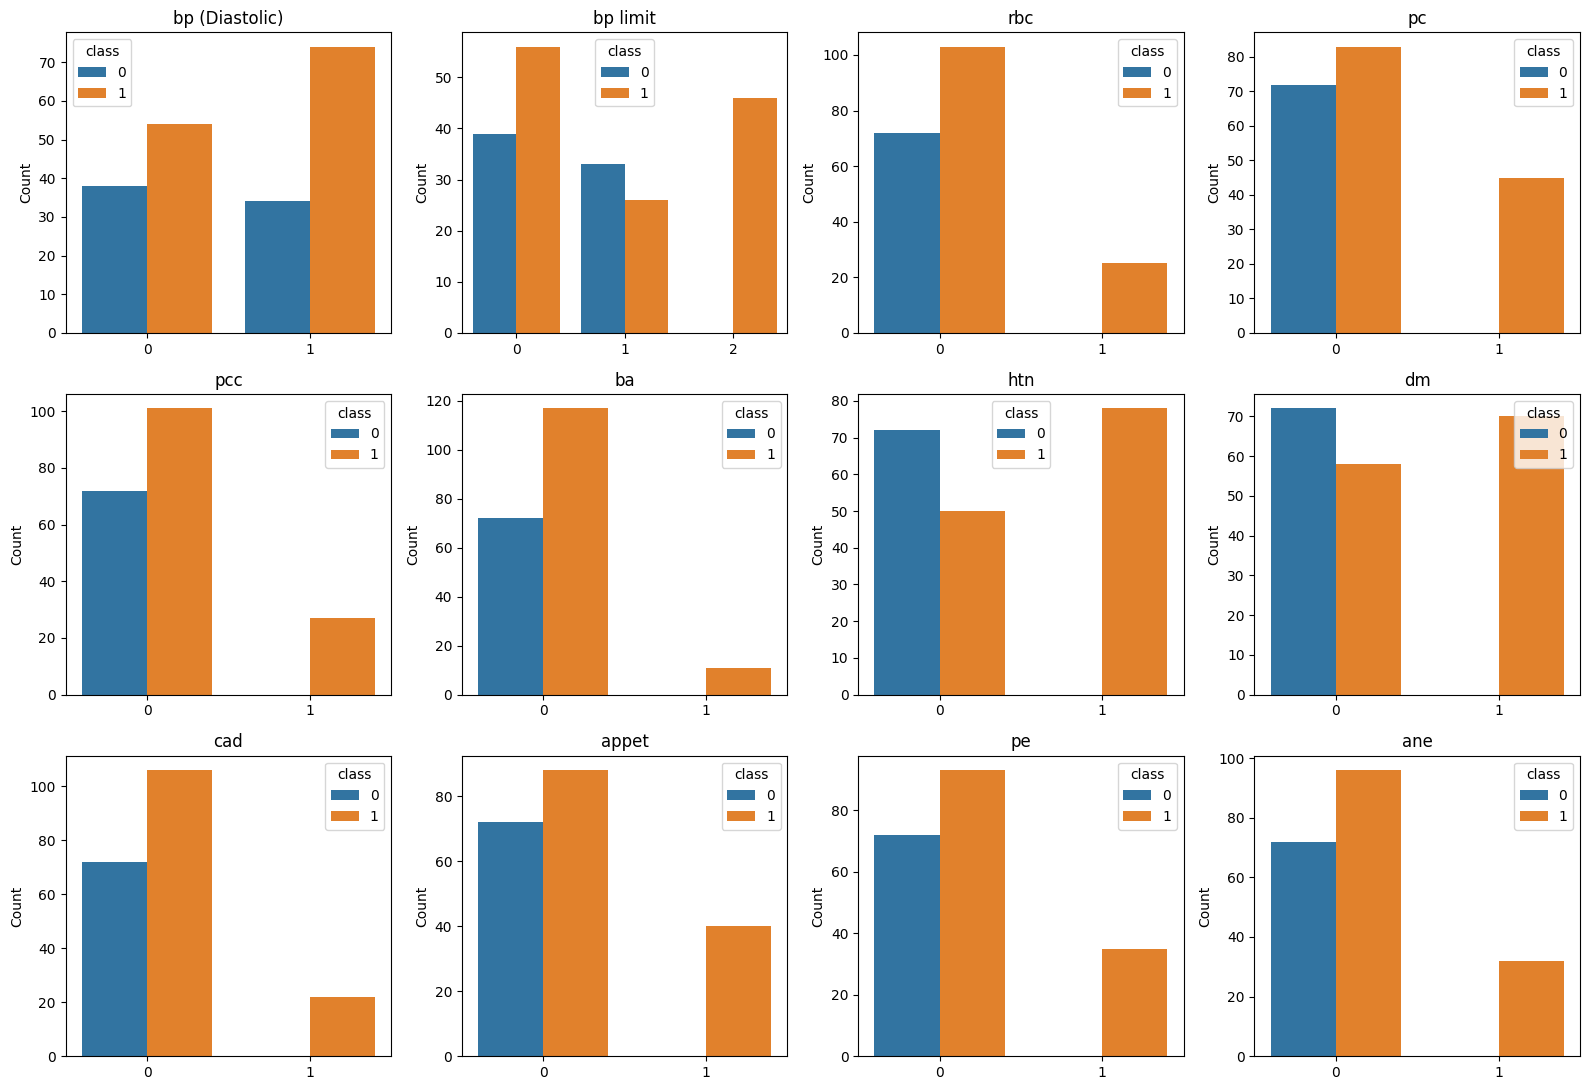

In [ ]:
# 9.1 — Binary clinical feature distributions
binary_features = ["bp (Diastolic)","bp limit","rbc","pc","pcc","ba","htn","dm","cad","appet","pe","ane"]

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for ax, col in zip(axes, binary_features):
    sns.countplot(data=pd.DataFrame({col: X_final[col], "class": y_final}), x=col, hue="class", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [ ]:
# 9.2 — CKD rate for binary clinical features

eda_binary = pd.DataFrame(X_final[binary_features])
eda_binary["target"] = y_final.values

for col in binary_features:
    rate = (eda_binary.groupby(col)["target"].mean().mul(100).round(2))
    print("\n")
    print(rate)



bp (Diastolic)
0    58.70
1    68.52
Name: target, dtype: float64


bp limit
0     58.95
1     44.07
2    100.00
Name: target, dtype: float64


rbc
0     58.86
1    100.00
Name: target, dtype: float64


pc
0     53.55
1    100.00
Name: target, dtype: float64


pcc
0     58.38
1    100.00
Name: target, dtype: float64


ba
0     61.9
1    100.0
Name: target, dtype: float64


htn
0     40.98
1    100.00
Name: target, dtype: float64


dm
0     44.62
1    100.00
Name: target, dtype: float64


cad
0     59.55
1    100.00
Name: target, dtype: float64


appet
0     55.0
1    100.0
Name: target, dtype: float64


pe
0     56.36
1    100.00
Name: target, dtype: float64


ane
0     57.14
1    100.00
Name: target, dtype: float64


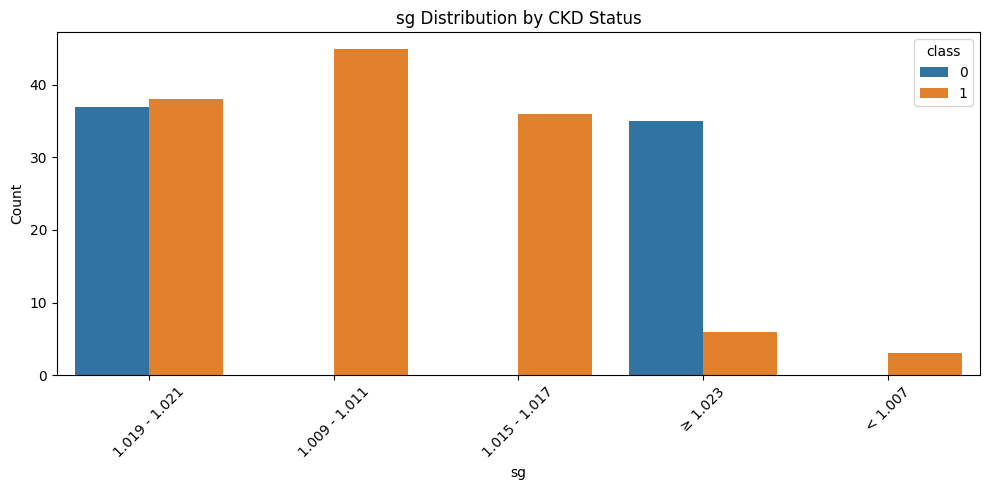

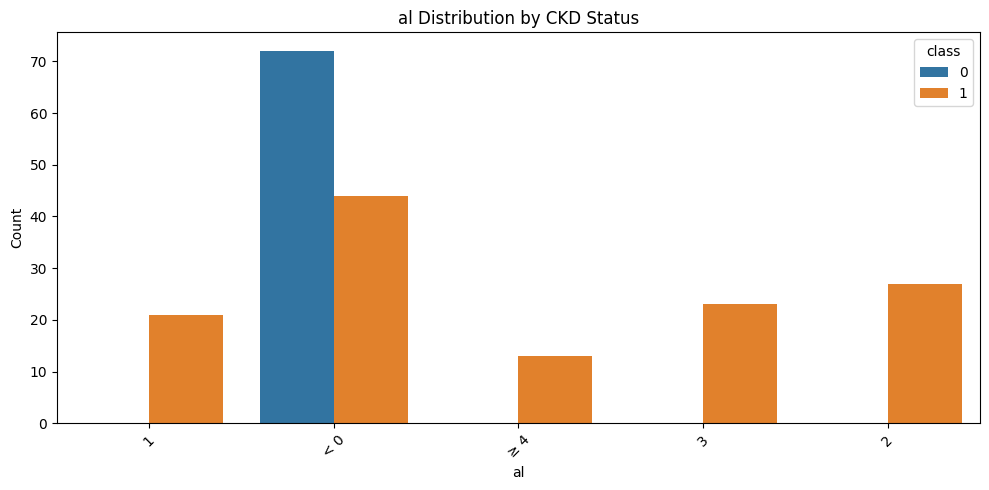

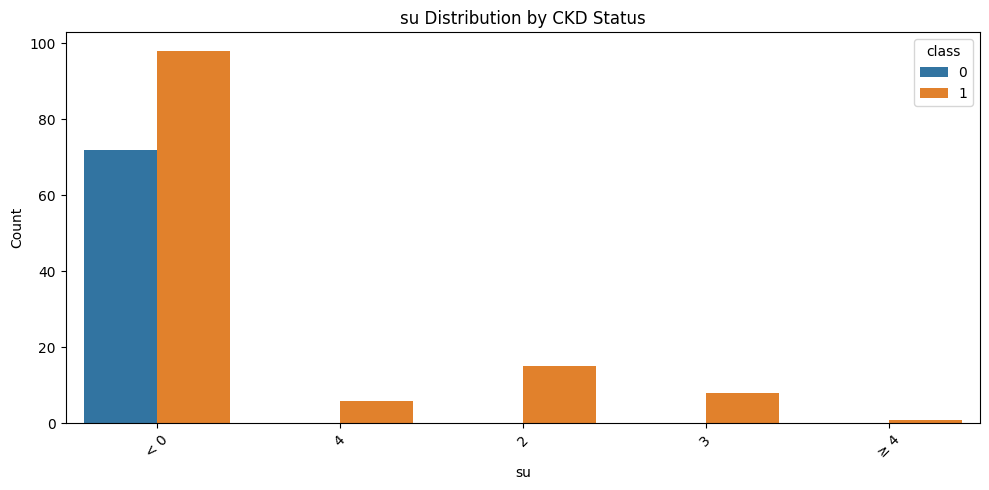

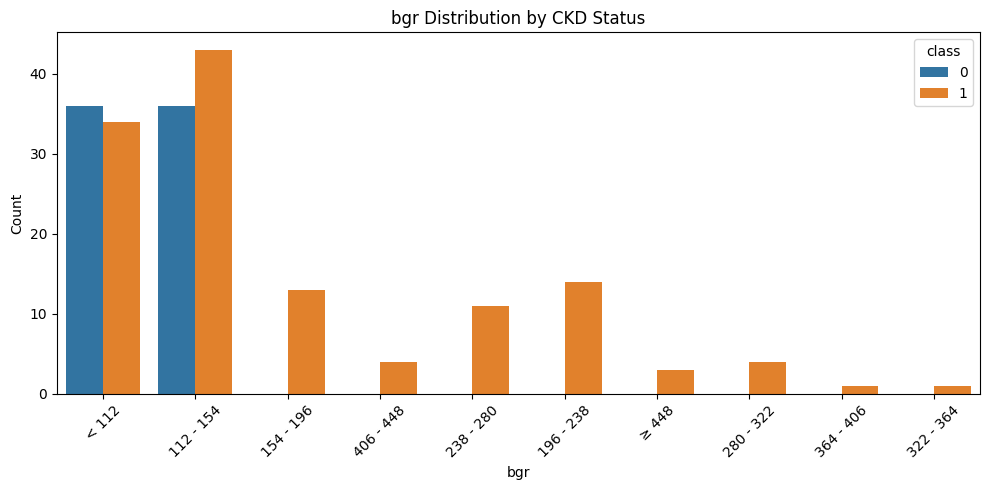

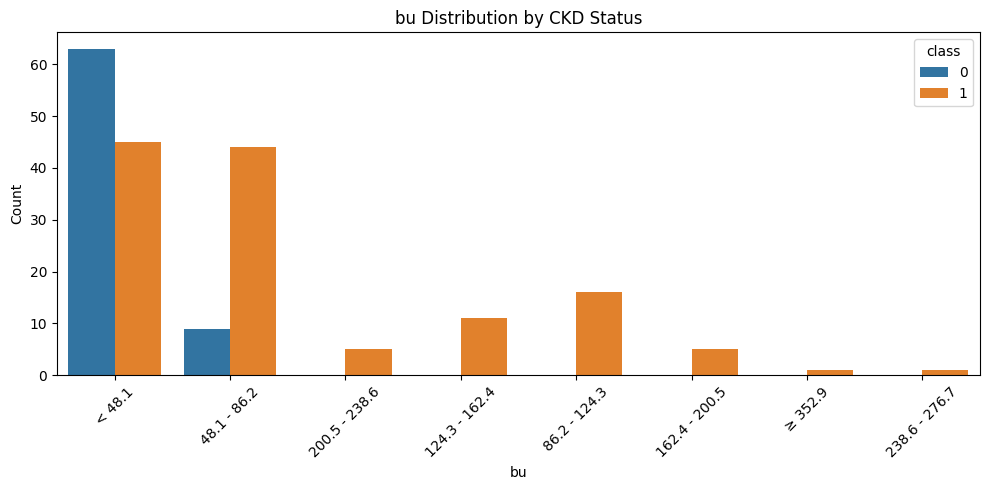

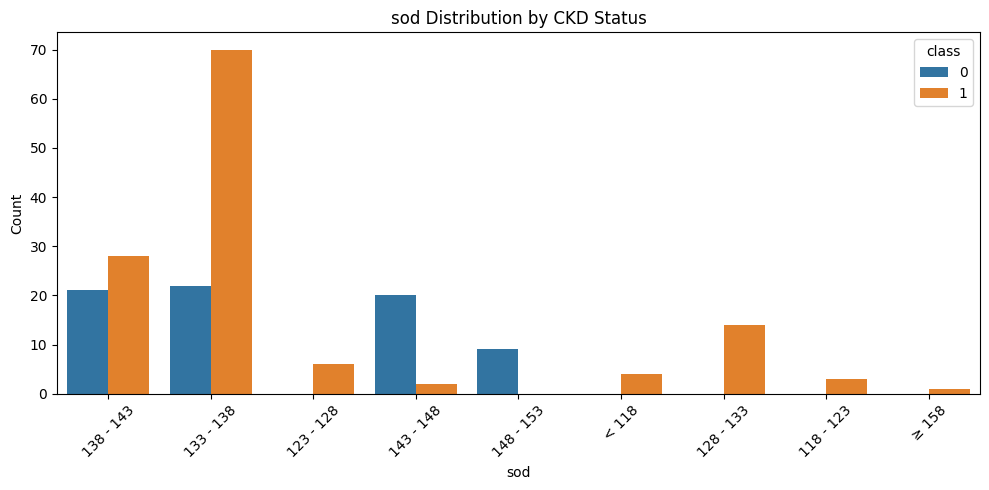

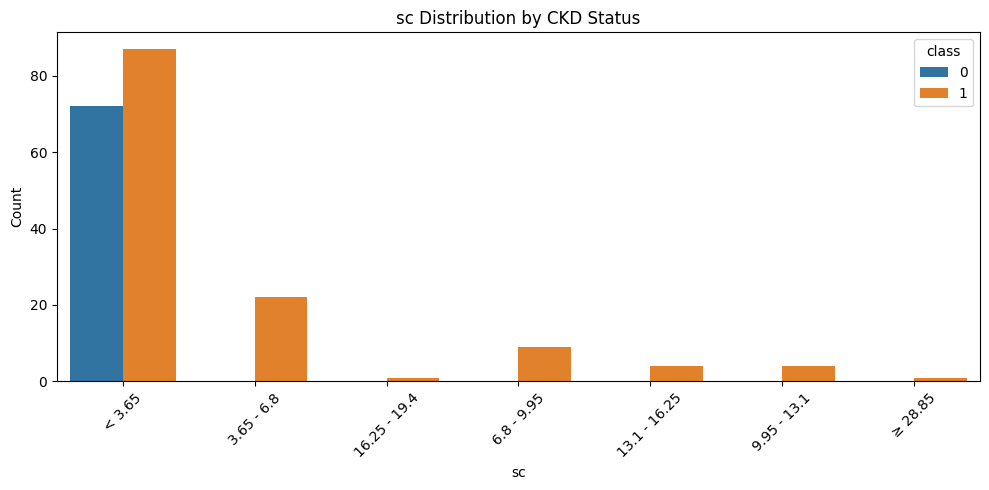

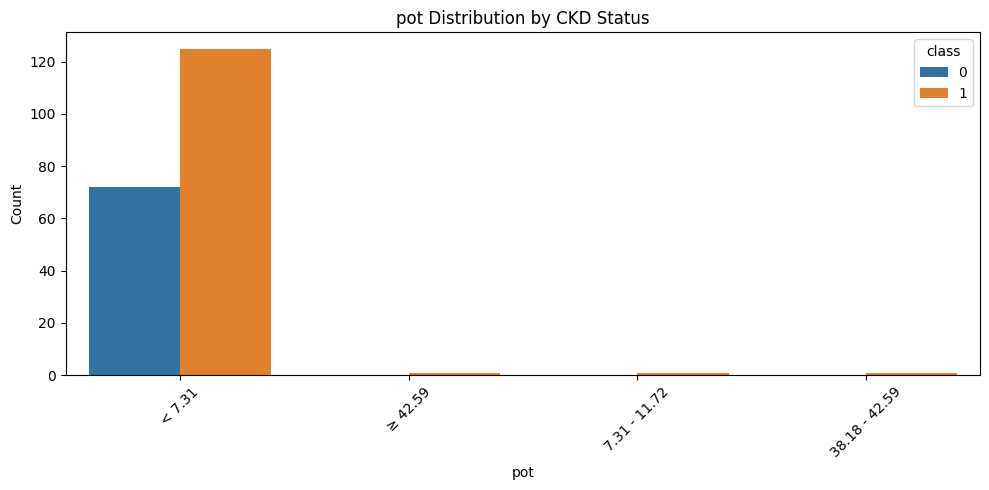

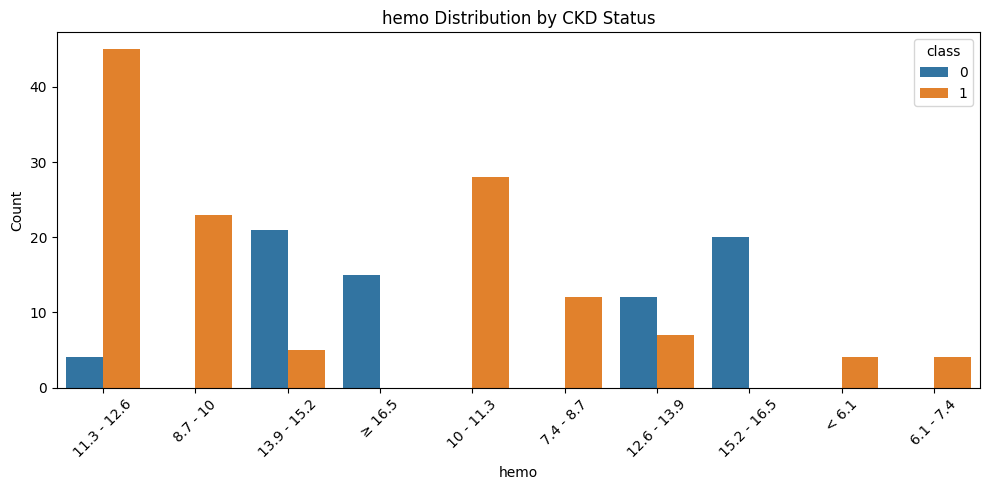

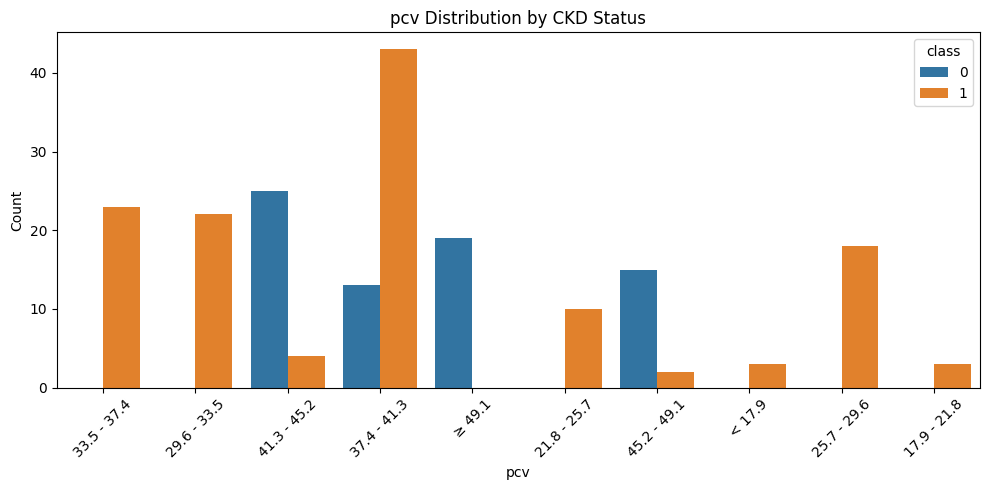

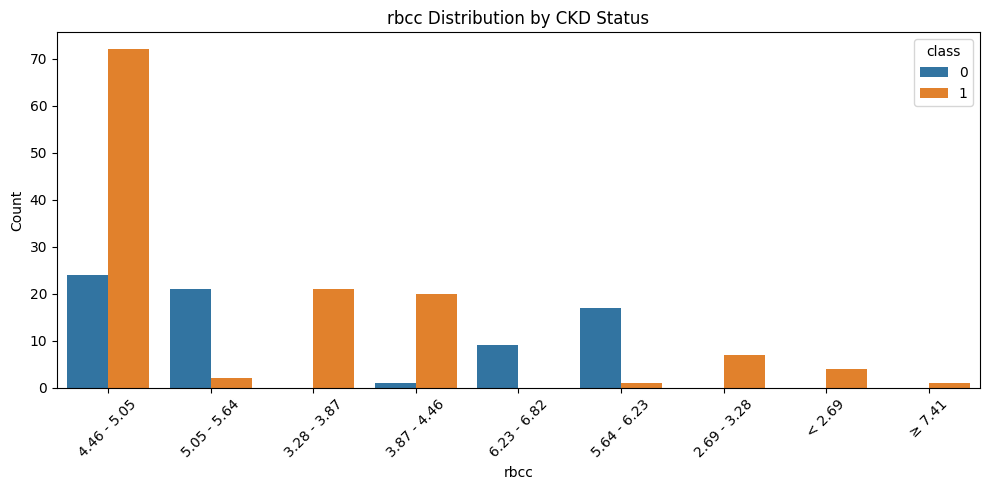

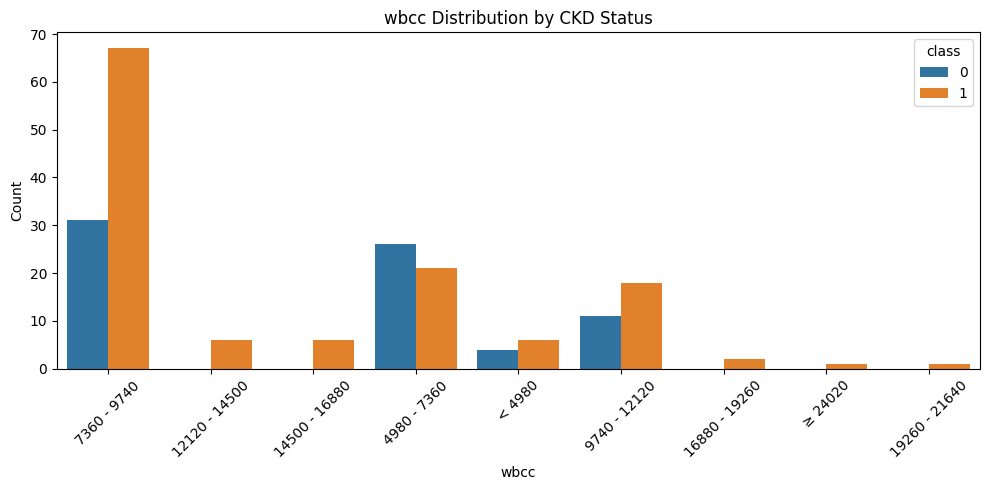

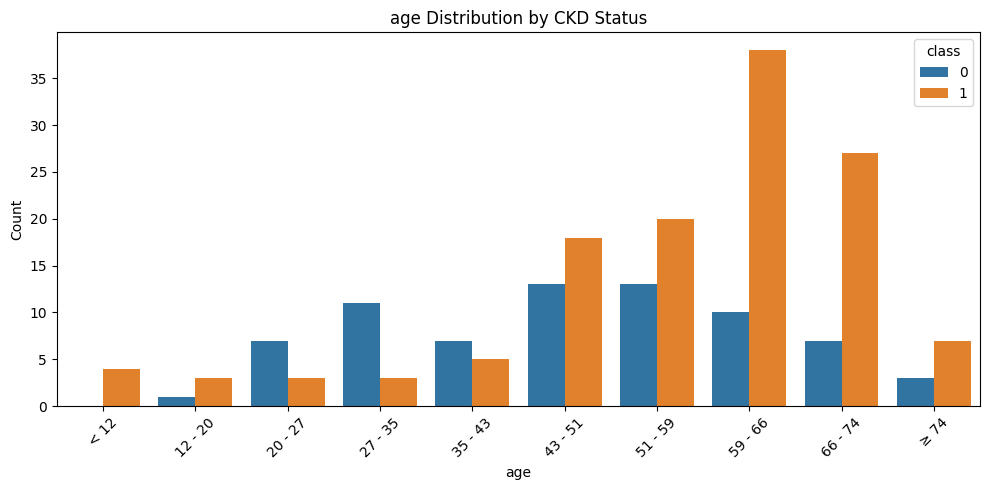

In [ ]:
# 9.3 Distribution of categorical clinical variables by CKD status

categorical_features = ["sg","al","su","bgr","bu","sod","sc","pot","hemo","pcv","rbcc","wbcc","age"]

eda_data = X_final.copy()
eda_data["class"] = y_final.values

for col in categorical_features:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=eda_data,x=col,hue="class")
    plt.title(f"{col} Distribution by CKD Status")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [ ]:
# 9.4 — CKD rate across categorical ranges

for col in categorical_features:
    rate = (eda_data.groupby(col)["class"].mean().mul(100).round(2).sort_values(ascending=False))
    print(f"\n{'='*60}")
    print(f"Feature: {col}")
    print("CKD percentage by category:")
    print(rate)


Feature: sg
CKD percentage by category:
sg
1.009 - 1.011    100.00
1.015 - 1.017    100.00
< 1.007          100.00
1.019 - 1.021     50.67
≥ 1.023           14.63
Name: class, dtype: float64

Feature: al
CKD percentage by category:
al
1      100.00
2      100.00
3      100.00
≥ 4    100.00
< 0     37.93
Name: class, dtype: float64

Feature: su
CKD percentage by category:
su
2      100.00
3      100.00
4      100.00
≥ 4    100.00
< 0     57.65
Name: class, dtype: float64

Feature: bgr
CKD percentage by category:
bgr
154 - 196    100.00
196 - 238    100.00
364 - 406    100.00
238 - 280    100.00
280 - 322    100.00
322 - 364    100.00
≥ 448        100.00
406 - 448    100.00
112 - 154     54.43
< 112         48.57
Name: class, dtype: float64

Feature: bu
CKD percentage by category:
bu
124.3 - 162.4    100.00
162.4 - 200.5    100.00
200.5 - 238.6    100.00
238.6 - 276.7    100.00
86.2 - 124.3     100.00
≥ 352.9          100.00
48.1 - 86.2       83.02
< 48.1            41.67
Name: class, d

Numeric features: ['bp (Diastolic)', 'bp limit', 'rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']


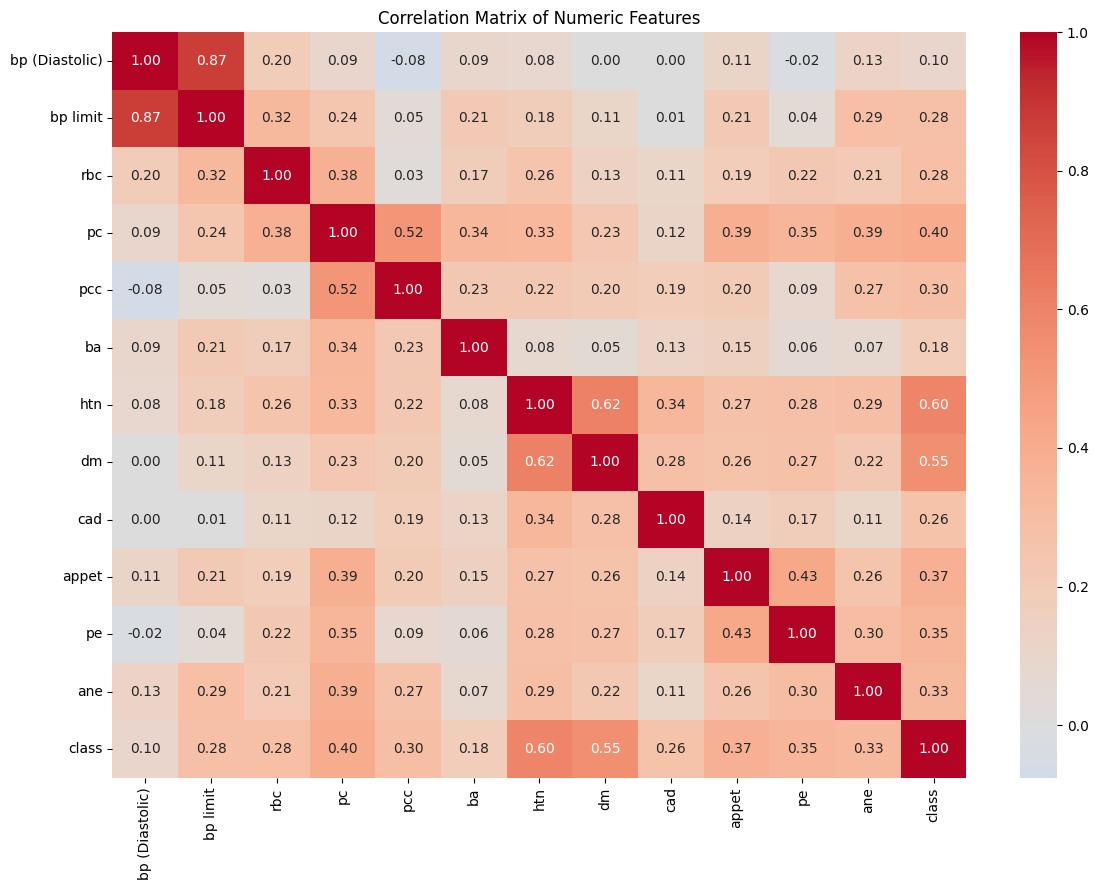

In [ ]:
# 9.5 — Correlation analysis of already-numeric features

numeric_features = X_final.select_dtypes(include=["int64", "float64"]).columns.tolist()
print("Numeric features:", numeric_features)

corr_data = X_final[numeric_features].copy()
corr_data["class"] = y_final.values

plt.figure(figsize=(12, 9))
sns.heatmap(corr_data.corr(),annot=True,fmt=".2f",cmap="coolwarm",center=0)
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

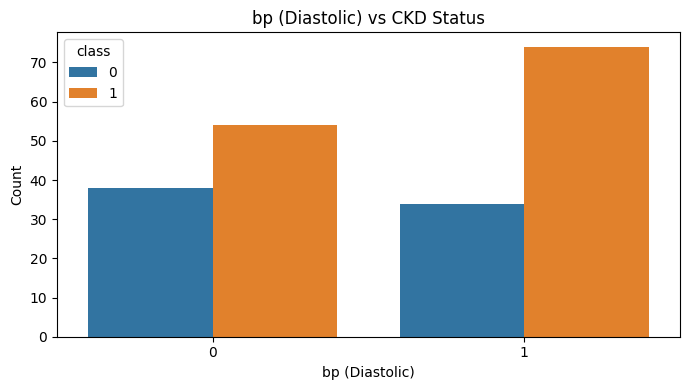

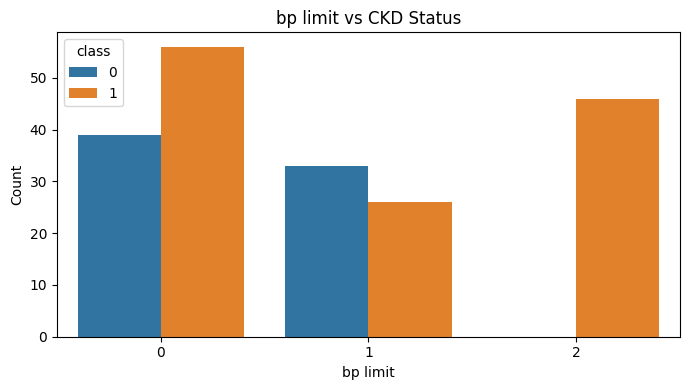

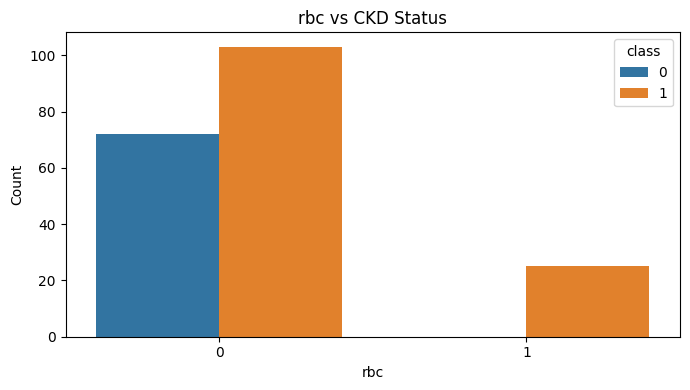

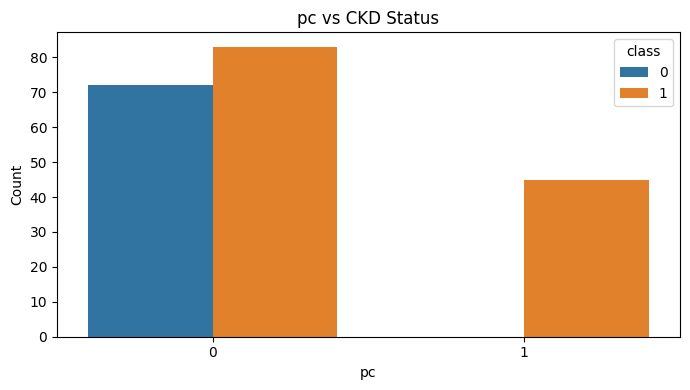

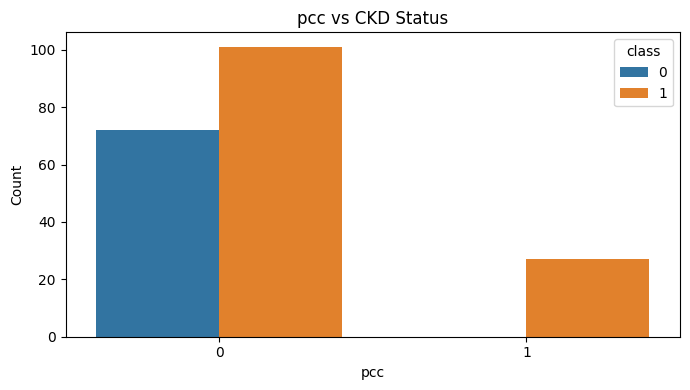

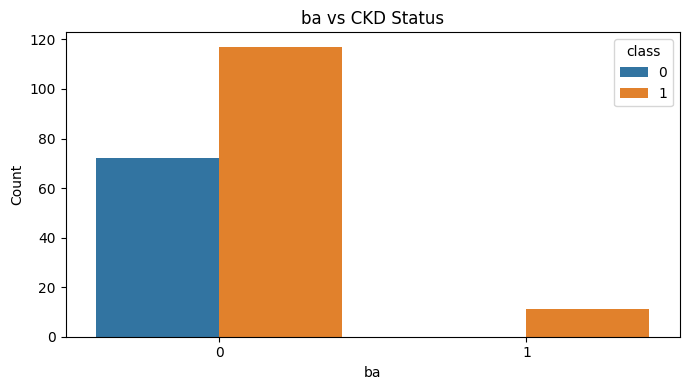

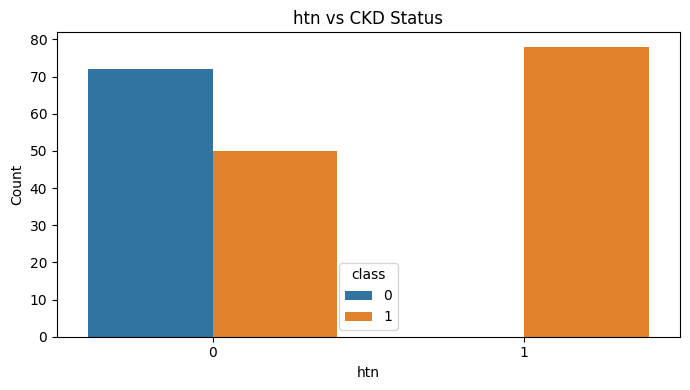

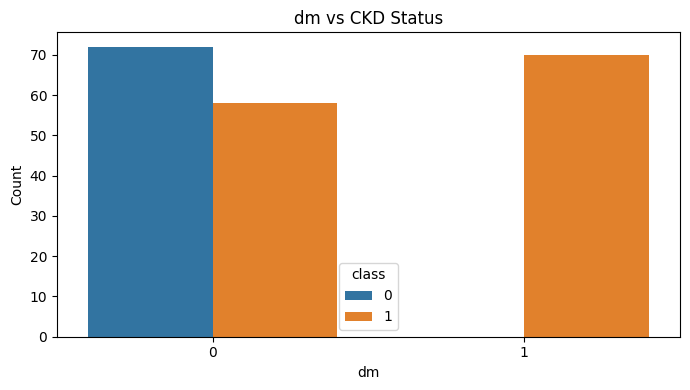

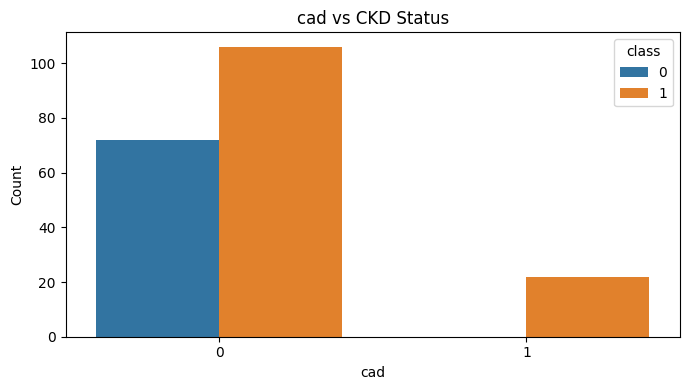

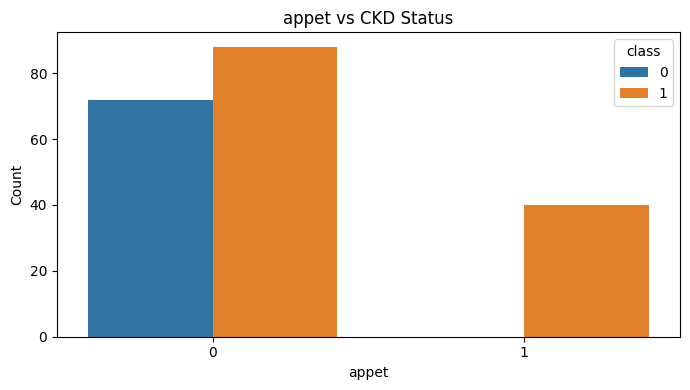

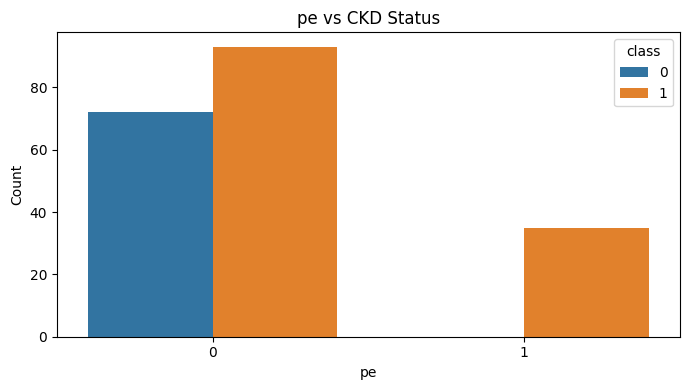

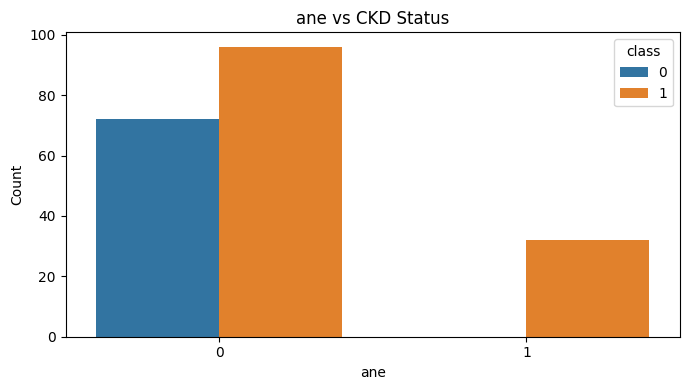

In [ ]:
# 9.6 — Numeric feature relationship with CKD
for col in numeric_features:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=eda_data,x=col,hue="class")
    plt.title(f"{col} vs CKD Status")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

## **Step 10 — Train/Test Split + Preprocessing Pipeline**

In [ ]:
# 10.1 Preparing the Final Data
from sklearn.model_selection import train_test_split

X_model = X_final.copy()
y_model = y_final.copy()
print("Features shape:", X_model.shape)
print("Target shape:", y_model.shape)

Features shape: (200, 25)
Target shape: (200,)


In [ ]:
# 10.2 — Train/Test split
X_train, X_test, y_train, y_test = train_test_split(X_model,y_model,test_size=0.20,stratify=y_model,random_state=42)
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())

Training samples: 160
Testing samples: 40

Training target distribution:
class
1    102
0     58
Name: count, dtype: int64

Testing target distribution:
class
1    26
0    14
Name: count, dtype: int64


In [ ]:
# 10.3 — Identify numeric and categorical features
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['bp (Diastolic)', 'bp limit', 'rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

Categorical features:
['sg', 'al', 'su', 'bgr', 'bu', 'sod', 'sc', 'pot', 'hemo', 'pcv', 'rbcc', 'wbcc', 'age']


In [ ]:
# 10.4 — Build preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
# 10.5 — Fit preprocessing only on training data

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (160, 108)
Processed testing shape: (40, 108)


In [ ]:
# 10.6 — Check generated feature names

feature_names = preprocessor.get_feature_names_out()
print("Number of processed features:", len(feature_names))
print("\nFirst 50 processed features:")
print(feature_names[:50])

Number of processed features: 108

First 50 processed features:
['num__bp (Diastolic)' 'num__bp limit' 'num__rbc' 'num__pc' 'num__pcc'
 'num__ba' 'num__htn' 'num__dm' 'num__cad' 'num__appet' 'num__pe'
 'num__ane' 'cat__sg_1.009 - 1.011' 'cat__sg_1.015 - 1.017'
 'cat__sg_1.019 - 1.021' 'cat__sg_< 1.007' 'cat__sg_≥ 1.023' 'cat__al_1'
 'cat__al_2' 'cat__al_3' 'cat__al_< 0' 'cat__al_≥ 4' 'cat__su_2'
 'cat__su_3' 'cat__su_4' 'cat__su_< 0' 'cat__su_≥ 4' 'cat__bgr_112 - 154'
 'cat__bgr_154 - 196' 'cat__bgr_196 - 238' 'cat__bgr_238 - 280'
 'cat__bgr_280 - 322' 'cat__bgr_322 - 364' 'cat__bgr_406 - 448'
 'cat__bgr_< 112' 'cat__bgr_≥ 448' 'cat__bu_124.3 - 162.4'
 'cat__bu_162.4 - 200.5' 'cat__bu_200.5 - 238.6' 'cat__bu_238.6 - 276.7'
 'cat__bu_48.1 - 86.2' 'cat__bu_86.2 - 124.3' 'cat__bu_< 48.1'
 'cat__bu_≥ 352.9' 'cat__sod_118 - 123' 'cat__sod_123 - 128'
 'cat__sod_128 - 133' 'cat__sod_133 - 138' 'cat__sod_138 - 143'
 'cat__sod_143 - 148']


## **Step 11 — Model Training and Comparison.**

In [ ]:
# 11.1 — Import models and metrics

import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,confusion_matrix,classification_report

# 11.2 — Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

print("Models created:")
for name in models:
    print("-", name)


Models created:
- Logistic Regression
- Random Forest
- XGBoost


In [ ]:
# 11.3 — 5-Fold Stratified Cross-Validation

cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []
for name, model in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )
    scores = cross_validate(pipeline,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values( by="ROC-AUC", ascending=False).reset_index(drop=True)
display(cv_results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.98125,0.981818,0.990476,0.985598,1.000
1,Random Forest,0.98125,0.990476,0.980952,0.985122,1.000
2,XGBoost,0.95625,0.980000,0.951429,0.964615,0.995


In [ ]:
# 11.4 — Show variation across folds

cv_detailed = []
for name, model in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    scores = cross_validate(pipeline,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    cv_detailed.append({
        "Model": name,

        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),

        "Precision Mean": scores["test_precision"].mean(),
        "Precision Std": scores["test_precision"].std(),

        "Recall Mean": scores["test_recall"].mean(),
        "Recall Std": scores["test_recall"].std(),

        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std(),

        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "ROC-AUC Std": scores["test_roc_auc"].std()
    })

cv_detailed_df = pd.DataFrame(cv_detailed)
display(cv_detailed_df)

,Model,Accuracy Mean,Accuracy Std,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,ROC-AUC Std
0,Logistic Regression,0.98125,0.025000,0.981818,0.036364,0.990476,0.019048,0.985598,0.019107,1.000,0.00
1,Random Forest,0.98125,0.025000,0.990476,0.019048,0.980952,0.038095,0.985122,0.019940,1.000,0.00
2,XGBoost,0.95625,0.054486,0.980000,0.040000,0.951429,0.061012,0.964615,0.043947,0.995,0.01


In [ ]:
# 11.5 — Select the best model based on CV ROC-AUC
best_model_name = cv_results_df.iloc[0]["Model"]

print("Best baseline model:")
print(best_model_name)

print("\nReason:")
print("Highest mean 5-fold cross-validation ROC-AUC.")

Best baseline model:
Logistic Regression

Reason:
Highest mean 5-fold cross-validation ROC-AUC.


**However, because the dataset has only 200 samples, we should not declare Logistic Regression as the final model yet. The next step is hyperparameter tuning and then evaluation on the untouched test set.**

## **Step 12 — Hyperparameter Tuning**

Tuning all three models using **GridSearchCV** with **stratified 5-fold CV**.

In [ ]:
# 12.1 — Define tuning pipelines

from sklearn.model_selection import GridSearchCV

tuning_pipelines = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=3000,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

In [ ]:
# 12.2 — Define parameter grids

param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__solver": ["liblinear", "lbfgs"],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "model__n_estimators": [200, 400, 600],
        "model__max_depth": [None, 5, 10, 15],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2"]
    },

    "XGBoost": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [2, 3, 4],
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0]
    }
}

In [ ]:
# 12.3 GridSearch CV

tuned_models = {}
tuning_results = []

for name in tuning_pipelines:
    print(f"\nTuning {name}...")
    grid_search = GridSearchCV(
        estimator=tuning_pipelines[name],
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    grid_search.fit(X_train, y_train)
    tuned_models[name] = grid_search
    tuning_results.append({
        "Model": name,
        "Best CV ROC-AUC": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })
    print("Best CV ROC-AUC:", grid_search.best_score_)
    print("Best parameters:")
    print(grid_search.best_params_)


Tuning Logistic Regression...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV ROC-AUC: 1.0
Best parameters:
{'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'liblinear'}

Tuning Random Forest...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best CV ROC-AUC: 1.0
Best parameters:
{'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Tuning XGBoost...
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best CV ROC-AUC: 0.9974999999999999
Best parameters:
{'model__colsample_bytree': 0.8, 'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__subsample': 0.8}


In [ ]:
# 12.4 — Compare tuned models

tuning_results_df = pd.DataFrame(tuning_results)
tuning_results_df = tuning_results_df.sort_values( by="Best CV ROC-AUC", ascending=False).reset_index(drop=True)
display(tuning_results_df)

,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,1.0000,"{'model__C': 0.1, 'model__class_weight': None,..."
1,Random Forest,1.0000,"{'model__max_depth': None, 'model__max_feature..."
2,XGBoost,0.9975,"{'model__colsample_bytree': 0.8, 'model__learn..."


In [ ]:
# 12.5 — Identify the tuned model

best_tuned_name = tuning_results_df.iloc[0]["Model"]
best_tuned_model = tuned_models[best_tuned_name].best_estimator_

print("Best tuned model:")
print(best_tuned_name)

print("\nBest CV ROC-AUC:")
print(tuned_models[best_tuned_name].best_score_)

print("\nBest parameters:")
print(tuned_models[best_tuned_name].best_params_)

Best tuned model:
Logistic Regression

Best CV ROC-AUC:
1.0

Best parameters:
{'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'liblinear'}


## **Step 13 — Final Test-Set Evaluation**

The tuning confirms that **Logistic Regression and Random Forest are tied at CV ROC-AUC = 1.000**, while **XGBoost** is slightly lower at **0.9975.**

But we must not select **Logistic Regression** as the final model yet. The decisive step is testing all tuned models on the **untouched test** set.

In [ ]:
# 13.1 — Evaluate all tuned models

test_results = []
for name, grid_search in tuned_models.items():
    model = grid_search.best_estimator_
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)
test_results_df = test_results_df.sort_values( by="ROC-AUC", ascending=False).reset_index(drop=True)
display(test_results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0,1.0
2,XGBoost,1.0,1.0,1.0,1.0,1.0


In [ ]:
# 13.2 — Classification reports

for name, grid_search in tuned_models.items():
    model = grid_search.best_estimator_
    y_pred = model.predict(X_test)
    print("\n" + "=" * 70)
    print(f"{name}")
    print("=" * 70)

    print(classification_report(y_test,y_pred,target_names=["Not CKD", "CKD"],digits=4))


Logistic Regression
              precision    recall  f1-score   support

     Not CKD     1.0000    1.0000    1.0000        14
         CKD     1.0000    1.0000    1.0000        26

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40


Random Forest
              precision    recall  f1-score   support

     Not CKD     1.0000    1.0000    1.0000        14
         CKD     1.0000    1.0000    1.0000        26

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.0000    1.0000        40


XGBoost
              precision    recall  f1-score   support

     Not CKD     1.0000    1.0000    1.0000        14
         CKD     1.0000    1.0000    1.0000        26

    accuracy                         1.0000        40
   macro avg     1.0000    1.0000    1.0000        40
weighted avg     1.0000    1.

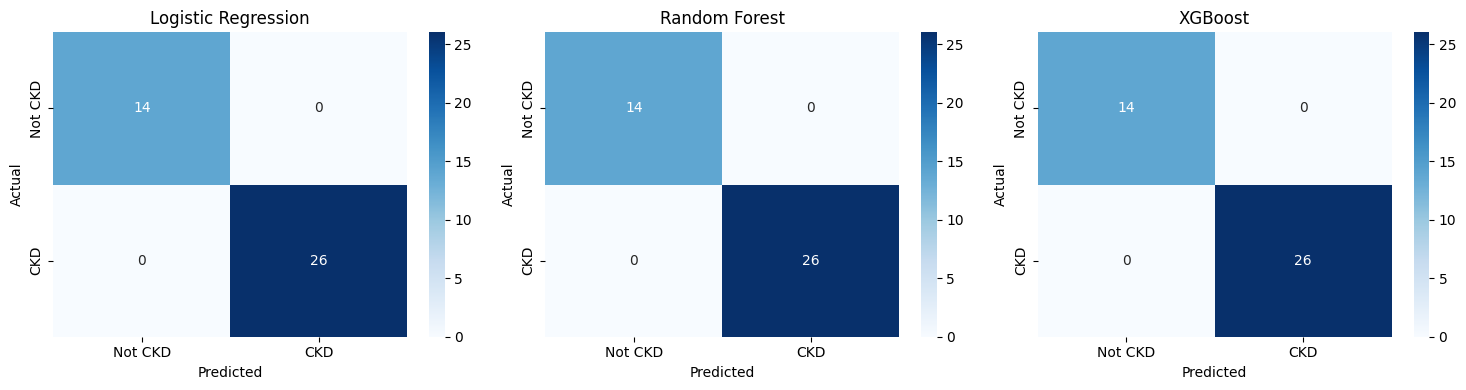

In [ ]:
# 13.3 — Confusion matrices

fig, axes = plt.subplots(1,len(tuned_models),figsize=(15, 4))
for ax, (name, grid_search) in zip( axes, tuned_models.items()):
    model = grid_search.best_estimator_
    y_pred = model.predict(X_test)
    cm = confusion_matrix( y_test, y_pred)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax,
        xticklabels=["Not CKD", "CKD"],
        yticklabels=["Not CKD", "CKD"]
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [ ]:
# 13.4 Selecting Final Model

best_test_model_name = test_results_df.iloc[0]["Model"]

final_model = tuned_models[best_test_model_name].best_estimator_
print("Final selected model:")
print(best_test_model_name)

print("\nFinal test performance:")
display(
    test_results_df[test_results_df["Model"] == best_test_model_name]
)

Final selected model:
Logistic Regression

Final test performance:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0


## **Step 14 — SHAP Explainability**

In [ ]:
# 14.1 Finalizing Model
final_model = tuned_models["Logistic Regression"].best_estimator_

# 14.2 — Separate preprocessing and classifier
final_preprocessor = final_model.named_steps["preprocessor"]
final_classifier = final_model.named_steps["model"]

# 14.3 Transforming Test Data
X_test_processed = final_preprocessor.transform(X_test)
feature_names = final_preprocessor.get_feature_names_out()
print("Processed test shape:", X_test_processed.shape)
print("Number of SHAP features:", len(feature_names))

Processed test shape: (40, 108)
Number of SHAP features: 108


In [ ]:
# 14.4 — Create SHAP explainer
import shap

explainer = shap.LinearExplainer(final_classifier,X_train_processed)
shap_values = explainer(X_test_processed)
print("SHAP explanation created successfully.")
print("SHAP shape:", shap_values.values.shape)

SHAP explanation created successfully.
SHAP shape: (40, 108)


In [ ]:
# 14.5 — Global SHAP feature importance

shap_importance = pd.DataFrame({"Feature": feature_names,"Mean_Absolute_SHAP": np.abs(shap_values.values).mean(axis=0)})
shap_importance = shap_importance.sort_values(by="Mean_Absolute_SHAP",ascending=False).reset_index(drop=True)
display(shap_importance.head(20))

,Feature,Mean_Absolute_SHAP
0,num__htn,0.523136
1,num__dm,0.459641
2,num__bp limit,0.249967
3,num__appet,0.208466
4,cat__rbcc_4.46 - 5.05,0.201572
5,num__pe,0.197544
6,num__pc,0.191505
7,num__ane,0.167455
8,cat__sod_133 - 138,0.159325
9,cat__hemo_11.3 - 12.6,0.159072


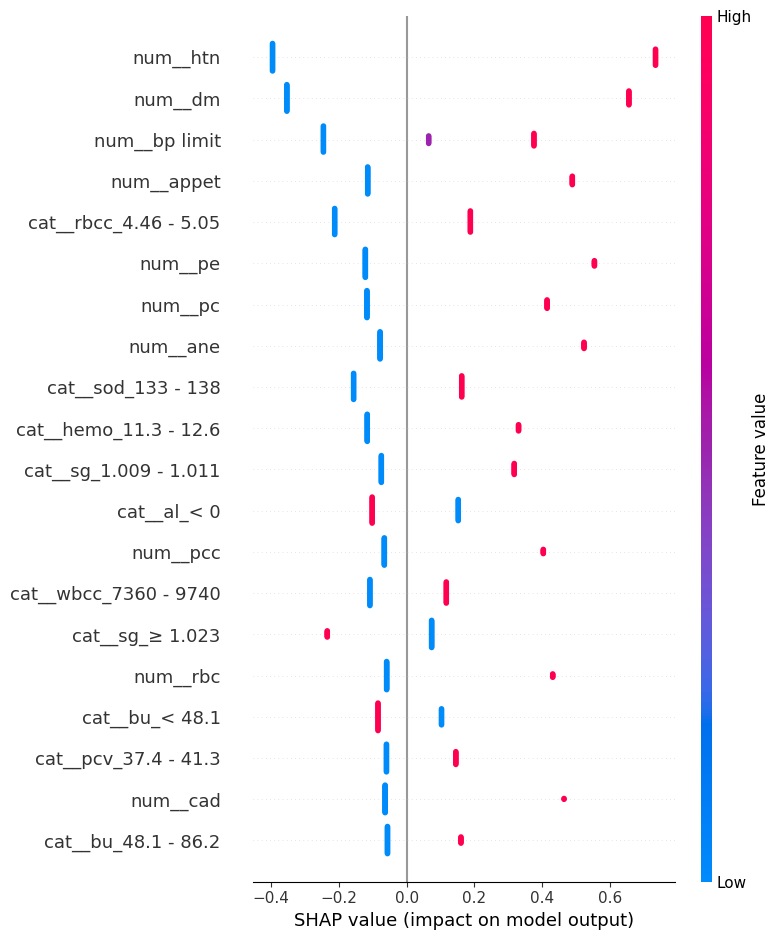

Actual class: 0
Predicted class: 0
Predicted CKD probability: 0.1097


In [ ]:
# 14.6 — SHAP summary plot
shap.summary_plot(shap_values,X_test_processed,feature_names=feature_names,max_display=20)

# 14.7 — Explain one individual patient
patient_index = 0
patient_prediction = final_model.predict(X_test.iloc[[patient_index]])[0]
patient_probability = final_model.predict_proba(X_test.iloc[[patient_index]])[0, 1]
print("Actual class:", y_test.iloc[patient_index])
print("Predicted class:", patient_prediction)
print("Predicted CKD probability:", round(patient_probability, 4))

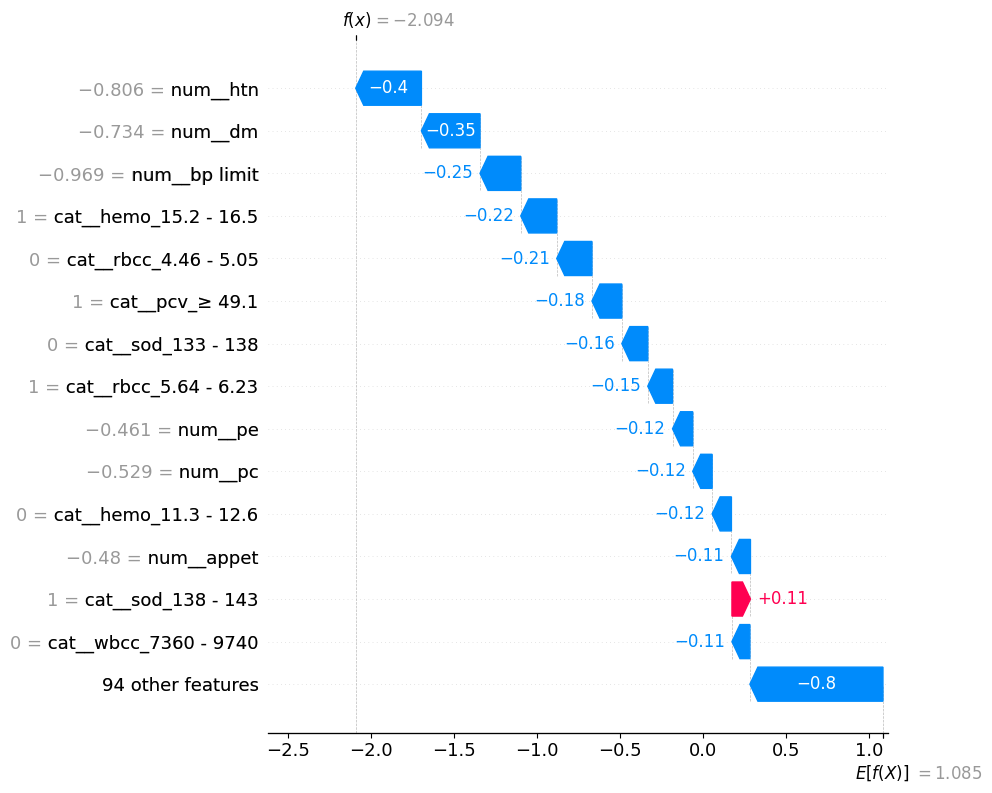

In [ ]:
# 14.8 — Individual SHAP waterfall

patient_index = 0

patient_shap = shap.Explanation(
    values=shap_values.values[patient_index],
    base_values=shap_values.base_values[patient_index],
    data=X_test_processed[patient_index],
    feature_names=feature_names
)

shap.plots.waterfall(patient_shap,max_display=15)

In [ ]:
# 14.9 — Generate Human-Readable SHAP Contributions

patient_shap_df = pd.DataFrame({
    "Feature": feature_names,
    "SHAP_Value": shap_values.values[patient_index],
    "Feature_Value": X_test_processed[patient_index]
})

patient_shap_df["Impact"] = np.where(
    patient_shap_df["SHAP_Value"] > 0,
    "Increases CKD prediction",
    "Decreases CKD prediction"
)

patient_shap_df["Absolute_Impact"] = ( patient_shap_df["SHAP_Value"].abs())
patient_shap_df = patient_shap_df.sort_values( "Absolute_Impact", ascending=False).reset_index(drop=True)
display(
    patient_shap_df[["Feature","Feature_Value","SHAP_Value","Impact"]].head(15)
)

,Feature,Feature_Value,SHAP_Value,Impact
0,num__htn,-0.805906,-0.395887,Decreases CKD prediction
1,num__dm,-0.733799,-0.353570,Decreases CKD prediction
2,num__bp limit,-0.969476,-0.245614,Decreases CKD prediction
3,cat__hemo_15.2 - 16.5,1.000000,-0.216850,Decreases CKD prediction
4,cat__rbcc_4.46 - 5.05,0.000000,-0.212392,Decreases CKD prediction
5,cat__pcv_≥ 49.1,1.000000,-0.180089,Decreases CKD prediction
6,cat__sod_133 - 138,0.000000,-0.156451,Decreases CKD prediction
7,cat__rbcc_5.64 - 6.23,1.000000,-0.149243,Decreases CKD prediction
8,num__pe,-0.460566,-0.121774,Decreases CKD prediction
9,num__pc,-0.529150,-0.117031,Decreases CKD prediction


In [ ]:
# 14.10 — Separate Risk-Increasing and Risk-Decreasing Factors

risk_increasing = patient_shap_df[patient_shap_df["SHAP_Value"] > 0].head(10)
risk_decreasing = patient_shap_df[patient_shap_df["SHAP_Value"] < 0].sort_values("SHAP_Value").head(10)
print("Factors increasing CKD prediction:")
display(risk_increasing[["Feature", "SHAP_Value"]])

print("\nFactors decreasing CKD prediction:")
display(risk_decreasing[["Feature", "SHAP_Value"]])

Factors increasing CKD prediction:


,Feature,SHAP_Value
12,cat__sod_138 - 143,0.111513
15,num__bp (Diastolic),0.085863
19,cat__sg_≥ 1.023,0.073976
28,cat__pcv_41.3 - 45.2,0.038739
33,cat__wbcc_4980 - 7360,0.029957
34,cat__bgr_< 112,0.025538
35,cat__rbcc_5.05 - 5.64,0.023509
36,cat__hemo_13.9 - 15.2,0.023368
37,cat__sod_143 - 148,0.022900
46,cat__hemo_≥ 16.5,0.013713



Factors decreasing CKD prediction:


,Feature,SHAP_Value
0,num__htn,-0.395887
1,num__dm,-0.353570
2,num__bp limit,-0.245614
3,cat__hemo_15.2 - 16.5,-0.216850
4,cat__rbcc_4.46 - 5.05,-0.212392
5,cat__pcv_≥ 49.1,-0.180089
6,cat__sod_133 - 138,-0.156451
7,cat__rbcc_5.64 - 6.23,-0.149243
8,num__pe,-0.121774
9,num__pc,-0.117031


## **Step 15 — Build the RenalInsight Prediction + SHAP Function**

In [ ]:
# 15.1 Prediction Function

def renalinsight_predict(patient_data):
    """
    Generate CKD prediction and SHAP explanation.

    Parameters
    ----------
    patient_data : pandas.DataFrame
        One-row DataFrame containing the original 25 model input features.

    Returns
    -------
    result : dict
        Prediction, probability and SHAP explanations.
    """

    # 1.Prediction
    prediction = final_model.predict(patient_data)[0]
    probability = final_model.predict_proba(patient_data)[0, 1]

    # 2. Risk category
    if probability < 0.30:
        risk_level = "Low"
    elif probability < 0.70:
        risk_level = "Moderate"
    else:
        risk_level = "High"

    # 3. Transform patient
    processed_patient = final_preprocessor.transform(patient_data)

    # 4. SHAP explanation
    patient_explanation = explainer(processed_patient )

    shap_values_patient = patient_explanation.values[0]

    # 5. SHAP table
    shap_df = pd.DataFrame({"feature": feature_names,"shap_value": shap_values_patient,"absolute_shap": np.abs(shap_values_patient) })

    shap_df = shap_df.sort_values( "absolute_shap", ascending=False).reset_index(drop=True)

    # 6. Positive contributors
    increasing = shap_df[
        shap_df["shap_value"] > 0
    ].copy()

    increasing = increasing.head(10)

    # 7. Negative contributors
    decreasing = shap_df[shap_df["shap_value"] < 0].copy()

    decreasing = decreasing.sort_values("shap_value").head(10)

    # 8. Final result
    result = {
        "prediction": ( "CKD" if prediction == 1 else "Not CKD"),

        "ckd_probability": round(float(probability),4
        ),

        "risk_level": risk_level,

        "risk_increasing_factors":
            increasing[
                ["feature", "shap_value"]
            ].to_dict("records"),

        "risk_decreasing_factors":
            decreasing[
                ["feature", "shap_value"]
            ].to_dict("records")
    }

    return result

In [ ]:
# 15.2 — Test it using an existing patient

sample_patient = X_test.iloc[[0]].copy()
result = renalinsight_predict( sample_patient )

print("Prediction:")
print(result["prediction"])

print("\nCKD Probability:")
print(result["ckd_probability"])

print("\nRisk Level:")
print(result["risk_level"])

print("\nFactors Increasing CKD Prediction:")
for item in result["risk_increasing_factors"]:
    print(item)

print("\nFactors Decreasing CKD Prediction:")
for item in result["risk_decreasing_factors"]:
    print(item)

Prediction:
Not CKD

CKD Probability:
0.1097

Risk Level:
Low

Factors Increasing CKD Prediction:
{'feature': 'cat__sod_138 - 143', 'shap_value': 0.111513066839489}
{'feature': 'num__bp (Diastolic)', 'shap_value': 0.0858632727083423}
{'feature': 'cat__sg_≥ 1.023', 'shap_value': 0.07397624117682285}
{'feature': 'cat__pcv_41.3 - 45.2', 'shap_value': 0.038739461896364964}
{'feature': 'cat__wbcc_4980 - 7360', 'shap_value': 0.029957196713798664}
{'feature': 'cat__bgr_< 112', 'shap_value': 0.02553797991953758}
{'feature': 'cat__rbcc_5.05 - 5.64', 'shap_value': 0.023508932001124614}
{'feature': 'cat__hemo_13.9 - 15.2', 'shap_value': 0.023368352051878292}
{'feature': 'cat__sod_143 - 148', 'shap_value': 0.02290040192865536}
{'feature': 'cat__hemo_≥ 16.5', 'shap_value': 0.01371260195973073}

Factors Decreasing CKD Prediction:
{'feature': 'num__htn', 'shap_value': -0.3958867794877442}
{'feature': 'num__dm', 'shap_value': -0.3535698008146129}
{'feature': 'num__bp limit', 'shap_value': -0.245613899

## **Step 16 — Save the Final Model + SHAP Explainer**

In [ ]:
import os
import joblib
import json

# 16.1 Making Directory
MODEL_DIR = "renalinsight_models"
os.makedirs(MODEL_DIR, exist_ok=True)
print("Model directory created:", MODEL_DIR)

# 16.2 — Save SHAP explainer
model_path = os.path.join( MODEL_DIR, "final_model.joblib")
joblib.dump( final_model, model_path)
print("Final model saved successfully!")
print("Path:", model_path)

# 16.3 — Save SHAP explainer
shap_path = os.path.join( MODEL_DIR, "shap_explainer.joblib")
joblib.dump( explainer, shap_path)
print("SHAP explainer saved successfully!")
print("Path:", shap_path)

# 16.4 - Save feature names
feature_names_path = os.path.join( MODEL_DIR, "feature_names.joblib")
joblib.dump( feature_names, feature_names_path)
print("Feature names saved successfully!")
print("Number of transformed features:", len(feature_names))

# 16.5 — Saving Model Metadata
metadata = {
    "model_type": "Logistic Regression",
    "target": "class",
    "positive_class": "CKD",
    "negative_class": "Not CKD",
    "dataset_rows": 200,
    "dataset_features": 28,
    "cv_roc_auc": 1.0,
    "test_accuracy": 1.0,
    "test_precision": 1.0,
    "test_recall": 1.0,
    "test_f1": 1.0,
    "shap_enabled": True
}
metadata_path = os.path.join( MODEL_DIR, "model_metadata.json")
with open(metadata_path, "w") as f:
    json.dump( metadata, f, indent=4)
print("Metadata saved successfully!")


# 16.6 — Verify that everything was saved
print("\nSaved RenalInsight artifacts:")
print("=" * 50)

for filename in os.listdir(MODEL_DIR):
    filepath = os.path.join(MODEL_DIR, filename)
    size_kb = os.path.getsize(filepath) / 1024
    print(f"{filename:<30} : {size_kb:.2f} KB")

Model directory created: renalinsight_models
Final model saved successfully!
Path: renalinsight_models/final_model.joblib
SHAP explainer saved successfully!
Path: renalinsight_models/shap_explainer.joblib
Feature names saved successfully!
Number of transformed features: 108
Metadata saved successfully!

Saved RenalInsight artifacts:
feature_names.joblib           : 2.44 KB
model_metadata.json            : 0.32 KB
shap_explainer.joblib          : 173.83 KB
final_model.joblib             : 8.26 KB


In [ ]:
# Downloading ZIP

import os
import shutil
from google.colab import files

MODEL_DIR = "renalinsight_models"
ZIP_NAME = "RenalInsight_Model_Artifacts"

# Create ZIP
zip_path = shutil.make_archive(ZIP_NAME,"zip",MODEL_DIR)

print("ZIP created successfully!")
print("File:", zip_path)

# Automatic download
files.download(zip_path)

ZIP created successfully!
File: /content/RenalInsight_Model_Artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>